In [47]:
from dotenv import load_dotenv
load_dotenv()

True

In [48]:
from langchain_ollama import OllamaEmbeddings,ChatOllama
from langgraph.types import interrupt,Command
from langgraph.checkpoint.memory import InMemorySaver
from typing import Literal
from pydantic import BaseModel,Field
from langgraph.graph import StateGraph,START,END

In [49]:
llm=ChatOllama(model="gemma4:31b-cloud")
memory=InMemorySaver()

In [50]:
class SharedState(BaseModel):
    query:str=''
    draft_email:str=""
    human_feedback:str=""
    final_email:str=''

# **Nodes**

In [51]:
def draft_Node(state:SharedState)->SharedState:
    if state.human_feedback:
        draft=llm.invoke(f"""
                            Rewrite the email for the query :{state.query},
                            You already wrote this draft email : {state.draft_email},
                            This is the human feedback for the draft email :{state.human_feedback}
                        """)
    else:
        draft=llm.invoke(state.query)
    state.draft_email=draft.content
    return state

In [52]:
def human_feedback_Node(state:SharedState)->SharedState:
    feedback=interrupt({
        "draft_email":state.draft_email,
        "question":"if you want to send this email or rewrite the email ?"
    })
    fb=(feedback or "").strip().lower()

    if fb in ("yes","approve","ok","send"):
        state.human_feedback=""
        return state 
    else:
        state.human_feedback=feedback
        return state

In [53]:
def conditional_routing(state:SharedState)->Literal["draft","final"]:
    if state.human_feedback:
        return "draft"
    else:
        return "final"

In [54]:
def final_node(state:SharedState)->SharedState:
    if state.human_feedback:
        state.final_email=state.human_feedback
        return state
    else:
        print("Email Sent Successfully...")
        state.final_email="Email Sent Successfully"
        return state

In [55]:
graph_builder=StateGraph(SharedState)
graph_builder.add_node("draft",draft_Node)
graph_builder.add_node("human",human_feedback_Node)
graph_builder.add_node("final",final_node)

graph_builder.add_edge(START,"draft")
graph_builder.add_edge("draft","human")
graph_builder.add_conditional_edges("human",conditional_routing)
graph_builder.add_edge("final",END)

graph=graph_builder.compile(checkpointer=memory)

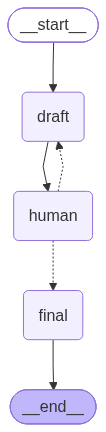

In [56]:
from IPython.display import Image
Image(graph.get_graph().draw_mermaid_png())

In [57]:
config={"configurable":{"thread_id":"1221"}}

In [58]:
res=graph.invoke({"query":"write an email for medical leave on 4th -9th November"},config=config)
res

{'query': 'write an email for medical leave on 4th -9th November',
 'draft_email': 'Depending on who you are emailing (your boss or a professor) and how much detail you want to share, you may need a different tone. Here are three options:\n\n### Option 1: Professional & Direct (Best for most workplaces)\n*Use this if you have a good relationship with your manager and don\'t need to provide extensive medical details.*\n\n**Subject:** Medical Leave Absence - [Your Name]\n\nDear [Manager\'s Name],\n\nI am writing to request medical leave from **November 4th to November 9th**. I expect to return to work on [Date of return, e.g., November 10th].\n\nI will ensure that all my current tasks are up to date before my leave begins. While I am away, [Colleague\'s Name] has kindly agreed to be the point of contact for [Project/Task name].\n\nI have attached my medical certificate for your records. Thank you for your understanding.\n\nBest regards,\n\n[Your Name]\n\n---\n\n### Option 2: Short & Form

In [59]:
res=graph.invoke(Command(resume="write this to the HR at apex implemets "),config=config)

In [60]:
res

{'query': 'write an email for medical leave on 4th -9th November',
 'draft_email': 'Since you are emailing **HR at Apex Implements**, you want a tone that is professional, clear, and follows corporate protocol. HR typically cares most about the exact dates, the documentation (medical certificate), and the return date.\n\nDepending on how much you have already coordinated with your manager, choose one of these two versions:\n\n### Option 1: Formal & Complete (Recommended)\n*Use this if you are notifying HR for the first time and want to ensure all bases are covered.*\n\n**Subject:** Medical Leave Request - [Your Full Name] - Nov 4 to Nov 9\n\nDear HR Team,\n\nI am writing to formally request a medical leave of absence from **November 4th to November 9th**. I expect to resume my duties at Apex Implements on **November 10th**.\n\nI have attached my medical certificate to this email for your records. I have also informed my immediate supervisor, [Manager\'s Name], to ensure that my current

In [61]:
res=graph.invoke(Command(resume="Option 1 "),config=config)

In [62]:
res

{'query': 'write an email for medical leave on 4th -9th November',
 'draft_email': "Since you have selected **Option 1**, here is the clean, final version of the email ready for you to copy and paste. \n\nI have highlighted the sections in brackets **[ ]** where you need to insert your specific details.\n\n***\n\n**Subject:** Medical Leave Request - [Your Full Name] - Nov 4 to Nov 9\n\nDear HR Team,\n\nI am writing to formally request a medical leave of absence from **November 4th to November 9th**. I expect to resume my duties at Apex Implements on **November 10th**.\n\nI have attached my medical certificate to this email for your records. I have also informed my immediate supervisor, [Manager's Name], to ensure that my current responsibilities are covered during my absence.\n\nPlease let me know if there are any further forms or documentation required by the company for this leave.\n\nThank you for your assistance.\n\nBest regards,\n\n[Your Full Name]\n[Your Employee ID Number]\n[You

In [64]:
print(res['draft_email'])

Since you have selected **Option 1**, here is the clean, final version of the email ready for you to copy and paste. 

I have highlighted the sections in brackets **[ ]** where you need to insert your specific details.

***

**Subject:** Medical Leave Request - [Your Full Name] - Nov 4 to Nov 9

Dear HR Team,

I am writing to formally request a medical leave of absence from **November 4th to November 9th**. I expect to resume my duties at Apex Implements on **November 10th**.

I have attached my medical certificate to this email for your records. I have also informed my immediate supervisor, [Manager's Name], to ensure that my current responsibilities are covered during my absence.

Please let me know if there are any further forms or documentation required by the company for this leave.

Thank you for your assistance.

Best regards,

[Your Full Name]
[Your Employee ID Number]
[Your Department]

***

### 🚀 Quick Reminders before you send:
*   **Attach the file:** Ensure your medical ce

In [65]:
res=graph.invoke(Command(resume="approve"),config=config)

Email Sent Successfully...
